# Assignment 09: Naïve Bayes Classification

The Naïve Bayes classifier is built from scratch with plain Python and NumPy: class priors and conditional probabilities are estimated from frequency counts, classification uses the MAP score, and the conditional-independence assumption and prediction sensitivity are analysed empirically against the dataset. No built-in Naïve Bayes classifier is used for any prediction.

In [1]:
import csv
import math
from collections import Counter

import numpy as np
import matplotlib.pyplot as plt

plt.rcParams["figure.dpi"] = 110

DATA_PATH = "assignment09_flu_symptoms.csv"
CLASS = "Flu"


def print_table(headers, rows, aligns=None):
    rows = [[str(c) for c in row] for row in rows]
    headers = [str(h) for h in headers]
    widths = [max(len(h), *(len(r[i]) for r in rows)) for i, h in enumerate(headers)]
    aligns = aligns or ["<"] * len(headers)
    line = "  ".join(f"{h:{aligns[i]}{widths[i]}}" for i, h in enumerate(headers))
    print(line)
    print("-" * len(line))
    for row in rows:
        print("  ".join(f"{c:{aligns[i]}{widths[i]}}" for i, c in enumerate(row)))


with open(DATA_PATH, newline="") as handle:
    reader = csv.DictReader(handle)
    FEATURES = [c for c in reader.fieldnames if c != CLASS]
    ROWS = [dict(row) for row in reader]

CLASSES = sorted({r[CLASS] for r in ROWS})
VALUES = {f: sorted({r[f] for r in ROWS}) for f in FEATURES}

print(f"{len(ROWS)} samples")
print(f"features: {FEATURES}")
print(f"class: {CLASS} in {CLASSES}")

8 samples
features: ['Chills', 'RunnyNose', 'Headache', 'Fever']
class: Flu in ['N', 'Y']


The raw data is 8 labelled patient records with four categorical symptoms. `Headache` is ternary (`Mild`, `No`, `Strong`) and the remaining symptoms along with the class are binary.

In [2]:
print_table(FEATURES + [CLASS], [[r[f] for f in FEATURES + [CLASS]] for r in ROWS])

Chills  RunnyNose  Headache  Fever  Flu
---------------------------------------
Y       N          Mild      Y      N  
Y       Y          No        N      Y  
Y       N          Strong    Y      Y  
N       Y          Mild      Y      Y  
N       N          No        N      N  
N       Y          Strong    Y      Y  
N       Y          Strong    N      N  
Y       Y          Mild      Y      Y  


## Q1. Dataset Analysis and Probability Estimation

Every parameter is estimated by maximum likelihood, i.e. the relative frequency of the event in the training data:

$$P(\text{Flu}=v)=\frac{\text{count}(v)}{N}, \qquad P(a_i\,|\,v)=\frac{\text{count}(a_i, v)}{\text{count}(v)}.$$

There is no smoothing here, so the estimates are exact sample proportions.

In [3]:
class_counts = Counter(r[CLASS] for r in ROWS)
N = len(ROWS)
priors = {v: class_counts[v] / N for v in CLASSES}

counts = {f: {val: Counter() for val in VALUES[f]} for f in FEATURES}
for r in ROWS:
    for f in FEATURES:
        counts[f][r[f]][r[CLASS]] += 1

conditional = {
    f: {val: {v: counts[f][val][v] / class_counts[v] for v in CLASSES} for val in VALUES[f]}
    for f in FEATURES
}

print("Class priors")
print_table(
    ["Class (v)", f"count({CLASS}=v)", f"P({CLASS}=v)"],
    [[v, class_counts[v], f"{priors[v]:.4f}"] for v in CLASSES],
    aligns=["<", ">", ">"],
)

Class priors
Class (v)  count(Flu=v)  P(Flu=v)
---------------------------------
N                     3    0.3750
Y                     5    0.6250


In [4]:
print("Conditional probabilities P(a_i | v)")
table = []
for f in FEATURES:
    for val in VALUES[f]:
        table.append([
            f, val,
            counts[f][val]["Y"], counts[f][val]["N"],
            f"{conditional[f][val]['Y']:.4f}", f"{conditional[f][val]['N']:.4f}",
        ])
print_table(
    ["Symptom", "Value", "count(Y)", "count(N)", "P(a|Flu=Y)", "P(a|Flu=N)"],
    table,
    aligns=["<", "<", ">", ">", ">", ">"],
)

Conditional probabilities P(a_i | v)
Symptom    Value   count(Y)  count(N)  P(a|Flu=Y)  P(a|Flu=N)
-------------------------------------------------------------
Chills     N              2         2      0.4000      0.6667
Chills     Y              3         1      0.6000      0.3333
RunnyNose  N              1         2      0.2000      0.6667
RunnyNose  Y              4         1      0.8000      0.3333
Headache   Mild           2         1      0.4000      0.3333
Headache   No             1         1      0.2000      0.3333
Headache   Strong         2         1      0.4000      0.3333
Fever      N              1         2      0.2000      0.6667
Fever      Y              4         1      0.8000      0.3333


Each symptom block sums to 1 within a class, which is the consistency check for conditional probabilities.

In [5]:
for f in FEATURES:
    row = sum(conditional[f][val][v] for val in VALUES[f] for v in CLASSES if v == "Y")
    row_n = sum(conditional[f][val][v] for val in VALUES[f] for v in CLASSES if v == "N")
    print(f"{f:>10s}: sum P(a|Y) = {row:.4f}   sum P(a|N) = {row_n:.4f}")

    Chills: sum P(a|Y) = 1.0000   sum P(a|N) = 1.0000
 RunnyNose: sum P(a|Y) = 1.0000   sum P(a|N) = 1.0000
  Headache: sum P(a|Y) = 1.0000   sum P(a|N) = 1.0000
     Fever: sum P(a|Y) = 1.0000   sum P(a|N) = 1.0000


## Q2. Naïve Bayes Classifier from Scratch

The classifier assumes that symptoms are conditionally independent given the class, so the joint likelihood factorizes and each class receives the score

$$\text{Score}(v_j) = P(v_j)\prod_{i=1}^{n} P(a_i\,|\,v_j).$$

The predicted class is the one with the larger score (the MAP decision). Product scores can underflow, so the equivalent log-space form

$$\log \text{Score}(v_j) = \log P(v_j) + \sum_{i=1}^{n}\log P(a_i\,|\,v_j)$$

is implemented as well; it is monotone in the score and yields the same decision.

In [6]:
def score(x, v):
    s = priors[v]
    for f in FEATURES:
        s *= conditional[f][x[f]][v]
    return s


def predict(x):
    scores = {v: score(x, v) for v in CLASSES}
    return max(scores, key=scores.get), scores


def log_score(x, v):
    return math.log(priors[v]) + sum(math.log(conditional[f][x[f]][v]) for f in FEATURES)


def predict_log(x):
    scores = {v: log_score(x, v) for v in CLASSES}
    return max(scores, key=scores.get), scores


def posterior(scores):
    total = sum(scores.values())
    return {v: s / total for v, s in scores.items()}

In [7]:
patient = {"Chills": "Y", "RunnyNose": "N", "Headache": "Mild", "Fever": "Y"}
print(f"Patient: {patient}\n")

for v in CLASSES:
    terms = "  ".join(f"{conditional[f][patient[f]][v]:.4f}" for f in FEATURES)
    s = score(patient, v)
    print(f"Flu = {v}")
    print(f"  P(Flu={v})            = {priors[v]:.4f}")
    print(f"  likelihood factors    = {terms}")
    print(f"  Score(Flu={v})        = {priors[v]:.4f} x " +
          " x ".join(f"{conditional[f][patient[f]][v]:.4f}" for f in FEATURES) + f" = {s:.8f}")
    print(f"  log Score(Flu={v})    = {log_score(patient, v):.4f}\n")

scores = {v: score(patient, v) for v in CLASSES}
post = posterior(scores)
pred, _ = predict(patient)
for v in CLASSES:
    print(f"P(Flu={v} | patient) = {post[v]:.4f}")
print(f"\nPrediction: Flu = {pred}")

Patient: {'Chills': 'Y', 'RunnyNose': 'N', 'Headache': 'Mild', 'Fever': 'Y'}

Flu = N
  P(Flu=N)            = 0.3750
  likelihood factors    = 0.3333  0.6667  0.3333  0.3333
  Score(Flu=N)        = 0.3750 x 0.3333 x 0.6667 x 0.3333 x 0.3333 = 0.00925926
  log Score(Flu=N)    = -4.6821

Flu = Y
  P(Flu=Y)            = 0.6250
  likelihood factors    = 0.6000  0.2000  0.4000  0.8000
  Score(Flu=Y)        = 0.6250 x 0.6000 x 0.2000 x 0.4000 x 0.8000 = 0.02400000
  log Score(Flu=Y)    = -3.7297

P(Flu=N | patient) = 0.2784
P(Flu=Y | patient) = 0.7216

Prediction: Flu = Y


## Q3. Classify Multiple Unseen Patients

Six symptom combinations that do not appear in the dataset are classified. The two class scores and the normalized posterior are reported for each.

In [8]:
unseen = [
    {"Chills": "N", "RunnyNose": "N", "Headache": "Mild", "Fever": "Y"},
    {"Chills": "Y", "RunnyNose": "Y", "Headache": "No", "Fever": "Y"},
    {"Chills": "N", "RunnyNose": "N", "Headache": "No", "Fever": "Y"},
    {"Chills": "Y", "RunnyNose": "N", "Headache": "Strong", "Fever": "N"},
    {"Chills": "N", "RunnyNose": "Y", "Headache": "Mild", "Fever": "N"},
    {"Chills": "Y", "RunnyNose": "N", "Headache": "No", "Fever": "Y"},
]

known = {tuple(r[f] for f in FEATURES) for r in ROWS}
for p in unseen:
    assert tuple(p[f] for f in FEATURES) not in known, p

rows = []
for p in unseen:
    pred, s = predict(p)
    post = posterior(s)
    rows.append([
        p["Chills"], p["RunnyNose"], p["Headache"], p["Fever"],
        f"{s['Y']:.6f}", f"{s['N']:.6f}", f"{post['Y']:.4f}", pred,
    ])
print_table(
    ["Chills", "RunnyNose", "Headache", "Fever", "Score(Y)", "Score(N)", "P(Y|x)", "Pred"],
    rows,
    aligns=["<", "<", "<", "<", ">", ">", ">", "<"],
)

Chills  RunnyNose  Headache  Fever  Score(Y)  Score(N)  P(Y|x)  Pred
--------------------------------------------------------------------
N       N          Mild      Y      0.016000  0.018519  0.4635  N   
Y       Y          No        Y      0.048000  0.004630  0.9120  Y   
N       N          No        Y      0.008000  0.018519  0.3017  N   
Y       N          Strong    N      0.006000  0.018519  0.2447  N   
N       Y          Mild      N      0.016000  0.018519  0.4635  N   
Y       N          No        Y      0.012000  0.009259  0.5645  Y   


## Q4. Conditional Independence

Naïve Bayes multiplies one-symptom marginals, which equals the true joint only when $P(A,B\mid C) = P(A\mid C)P(B\mid C)$. The two sides are computed directly from the sample counts for several symptom pairs; any mismatch is the empirical violation of the assumption.

In [9]:
def joint_prob(a, aval, b, bval, v):
    n_ab = sum(1 for r in ROWS if r[CLASS] == v and r[a] == aval and r[b] == bval)
    return n_ab / class_counts[v], n_ab


pairs = [
    ("Chills", "Y", "RunnyNose", "Y"),
    ("Chills", "Y", "Fever", "Y"),
    ("Headache", "Strong", "Fever", "Y"),
    ("RunnyNose", "Y", "Fever", "Y"),
    ("Headache", "Mild", "Fever", "Y"),
]

rows = []
for a, aval, b, bval in pairs:
    for v in CLASSES:
        joint, n_ab = joint_prob(a, aval, b, bval, v)
        prod = conditional[a][aval][v] * conditional[b][bval][v]
        rows.append([
            f"({a}={aval}, {b}={bval})", v, n_ab,
            f"{joint:.4f}", f"{prod:.4f}", f"{joint - prod:+.4f}",
        ])
print_table(
    ["Pair", "Class", "n(A,B,C)", "P(A,B|C)", "P(A|C)P(B|C)", "Difference"],
    rows,
    aligns=["<", "<", ">", ">", ">", ">"],
)

Pair                        Class  n(A,B,C)  P(A,B|C)  P(A|C)P(B|C)  Difference
-------------------------------------------------------------------------------
(Chills=Y, RunnyNose=Y)     N             0    0.0000        0.1111     -0.1111
(Chills=Y, RunnyNose=Y)     Y             2    0.4000        0.4800     -0.0800
(Chills=Y, Fever=Y)         N             1    0.3333        0.1111     +0.2222
(Chills=Y, Fever=Y)         Y             2    0.4000        0.4800     -0.0800
(Headache=Strong, Fever=Y)  N             0    0.0000        0.1111     -0.1111
(Headache=Strong, Fever=Y)  Y             2    0.4000        0.3200     +0.0800
(RunnyNose=Y, Fever=Y)      N             0    0.0000        0.1111     -0.1111
(RunnyNose=Y, Fever=Y)      Y             3    0.6000        0.6400     -0.0400
(Headache=Mild, Fever=Y)    N             1    0.3333        0.1111     +0.2222
(Headache=Mild, Fever=Y)    Y             2    0.4000        0.3200     +0.0800


No pair satisfies the independence identity exactly. Each conditional distribution contributes several parameters estimated from only eight records, so many factor cells rest on a single observation and the product of marginals systematically differs from the observed joint.

## Q5. Probability Sensitivity Challenge

Three base patients are perturbed one symptom at a time. Raw scores are scale-dependent, so each change is also summarised by the change in the log-likelihood ratio

$$\Delta \text{LLR} = \log\frac{P(a_i^{\text{new}}\mid Y)\,P(a_i^{\text{old}}\mid N)}{P(a_i^{\text{old}}\mid Y)\,P(a_i^{\text{new}}\mid N)},$$

which is the amount added to the log-odds of flu when that single symptom is altered. Its magnitude ranks symptoms consistently across patients; its sign says which way the evidence pushes.

In [10]:
bases = [
    {"Chills": "Y", "RunnyNose": "N", "Headache": "Mild", "Fever": "Y"},
    {"Chills": "N", "RunnyNose": "Y", "Headache": "Strong", "Fever": "Y"},
    {"Chills": "Y", "RunnyNose": "Y", "Headache": "No", "Fever": "N"},
]


def llr_delta(f, old, new):
    return math.log((conditional[f][new]["Y"] * conditional[f][old]["N"]) /
                    (conditional[f][old]["Y"] * conditional[f][new]["N"]))


def fmt_scores(s):
    return f"{s['Y']:.6f} / {s['N']:.6f}"


changes = []
for base in bases:
    pred, s = predict(base)
    print(f"Base {base}  ->  Flu = {pred}   (Score Y/N = {fmt_scores(s)}, log-odds = {math.log(s['Y'] / s['N']):+.4f})")
    for f in FEATURES:
        for val in VALUES[f]:
            if val == base[f]:
                continue
            changed = dict(base)
            changed[f] = val
            p2, s2 = predict(changed)
            d_llr = llr_delta(f, base[f], val)
            flag = "" if p2 == pred else "   <-- prediction flips"
            print(f"  {f}: {base[f]} -> {val:<6s}  Score Y/N = {fmt_scores(s2)}  "
                  f"dLLR = {d_llr:+.4f}  pred = {p2}{flag}")
            changes.append((f, val, d_llr, s2["Y"] - s["Y"], s2["N"] - s["N"], p2 != pred))
    print()

Base {'Chills': 'Y', 'RunnyNose': 'N', 'Headache': 'Mild', 'Fever': 'Y'}  ->  Flu = Y   (Score Y/N = 0.024000 / 0.009259, log-odds = +0.9524)
  Chills: Y -> N       Score Y/N = 0.016000 / 0.018519  dLLR = -1.0986  pred = N   <-- prediction flips
  RunnyNose: N -> Y       Score Y/N = 0.096000 / 0.004630  dLLR = +2.0794  pred = Y
  Headache: Mild -> No      Score Y/N = 0.012000 / 0.009259  dLLR = -0.6931  pred = Y
  Headache: Mild -> Strong  Score Y/N = 0.024000 / 0.009259  dLLR = +0.0000  pred = Y
  Fever: Y -> N       Score Y/N = 0.006000 / 0.018519  dLLR = -2.0794  pred = N   <-- prediction flips

Base {'Chills': 'N', 'RunnyNose': 'Y', 'Headache': 'Strong', 'Fever': 'Y'}  ->  Flu = Y   (Score Y/N = 0.064000 / 0.009259, log-odds = +1.9333)
  Chills: N -> Y       Score Y/N = 0.096000 / 0.004630  dLLR = +1.0986  pred = Y
  RunnyNose: Y -> N       Score Y/N = 0.016000 / 0.018519  dLLR = -2.0794  pred = N   <-- prediction flips
  Headache: Strong -> Mild    Score Y/N = 0.064000 / 0.009259 

In [11]:
agg = {}
for f, val, d_llr, _, _, _ in changes:
    agg.setdefault(f, []).append(abs(d_llr))

print("Mean |dLLR| and number of prediction flips when a symptom is altered")
rows = []
for f in FEATURES:
    flips = sum(1 for c in changes if c[0] == f and c[5])
    rows.append([f, f"{np.mean(agg[f]):.4f}", f"{max(agg[f]):.4f}", f"{flips}/{len(agg[f])}"])
print_table(["Symptom", "mean |dLLR|", "max |dLLR|", "flips"],
            rows, aligns=["<", ">", ">", ">"])

Mean |dLLR| and number of prediction flips when a symptom is altered
Symptom    mean |dLLR|  max |dLLR|  flips
-----------------------------------------
Chills          1.0986      1.0986    2/3
RunnyNose       2.0794      2.0794    2/3
Headache        0.4621      0.6931    0/6
Fever           2.0794      2.0794    2/3


`Fever` and `RunnyNose` dominate: each contributes $|\Delta\text{LLR}| = 2.08$ because their class-conditional probabilities are the furthest apart ($0.8$ vs $0.2$ for `Y`, and their `N`-class estimates are far from the `Y`-class ones), and each flips the prediction in two of the three base patients. `Chills` is intermediate ($1.10$) and also flips two of three, because the base log-odds gaps are small. `Headache` never flips a prediction: its values are close to uniformly distributed within each class, so swapping them changes the likelihood ratio by at most $0.69$ (and by $0$ between `Mild` and `Strong`).

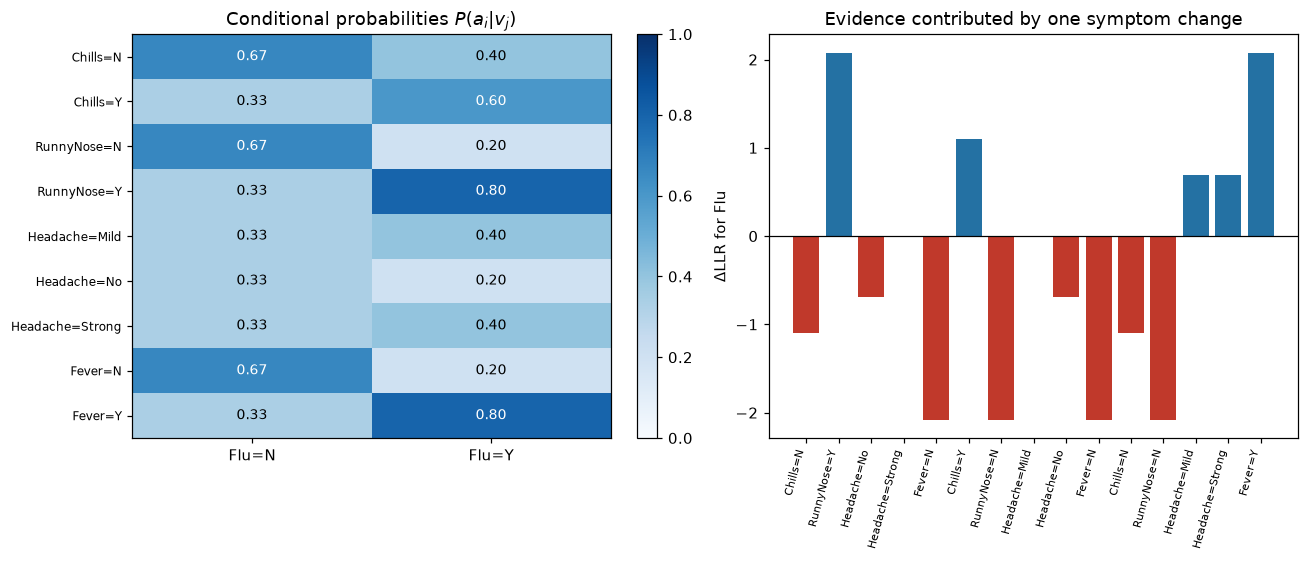

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5.2))
labels = [f"{f}={val}" for f in FEATURES for val in VALUES[f]]
matrix = np.array([[conditional[f][val][v] for v in CLASSES] for f in FEATURES for val in VALUES[f]])

im = axes[0].imshow(matrix, cmap="Blues", vmin=0, vmax=1, aspect="auto")
for i in range(matrix.shape[0]):
    for j in range(matrix.shape[1]):
        axes[0].text(j, i, f"{matrix[i, j]:.2f}", ha="center", va="center",
                     color="black" if matrix[i, j] < 0.6 else "white", fontsize=9)
axes[0].set_xticks(range(len(CLASSES)), [f"Flu={v}" for v in CLASSES])
axes[0].set_yticks(range(len(labels)), labels, fontsize=8)
axes[0].set_title("Conditional probabilities $P(a_i|v_j)$")
fig.colorbar(im, ax=axes[0], fraction=0.046)

per_value = [(f"{f}={val}", d_llr) for f, val, d_llr, *_ in changes]
x = np.arange(len(per_value))
colors = ["#c0392b" if d < 0 else "#2471a3" for _, d in per_value]
axes[1].bar(x, [d for _, d in per_value], color=colors)
axes[1].axhline(0, color="black", lw=0.8)
axes[1].set_xticks(x, [name for name, _ in per_value], rotation=75, ha="right", fontsize=7)
axes[1].set_ylabel("$\\Delta$LLR for Flu")
axes[1].set_title("Evidence contributed by one symptom change")
plt.tight_layout()
plt.show()

## Verification

The product score, the log score and an independent recomputation from the raw frequency counts are compared. The log form must preserve the ranking of the product form, and the count-based posteriors must match the closed-form computation.

In [13]:
def brute_force_posterior(x):
    joint = {}
    for v in CLASSES:
        num = class_counts[v] / N
        for f in FEATURES:
            num *= counts[f][x[f]][v] / class_counts[v]
        joint[v] = num
    total = sum(joint.values())
    return {v: joint[v] / total for v in CLASSES}


checks = unseen + [patient]
ok = True
for x in checks:
    s = {v: score(x, v) for v in CLASSES}
    ls = {v: log_score(x, v) for v in CLASSES}
    bf = brute_force_posterior(x)
    same_rank = max(s, key=s.get) == max(ls, key=ls.get)
    same_post = all(abs(posterior(s)[v] - bf[v]) < 1e-12 for v in CLASSES)
    ok &= same_rank and same_post
print(f"log-score ranking matches product-score ranking: {ok}")

try:
    from sklearn.naive_bayes import CategoricalNB
    from sklearn.preprocessing import OrdinalEncoder

    enc = OrdinalEncoder()
    X = enc.fit_transform([[r[f] for f in FEATURES] for r in ROWS])
    y = [r[CLASS] for r in ROWS]
    clf = CategoricalNB(alpha=0.0).fit(X, y)
    Xq = enc.transform([[x[f] for f in FEATURES] for x in checks])
    sk_pred = clf.predict(Xq)
    our_pred = [predict(x)[0] for x in checks]
    print(f"CategoricalNB predictions: {list(sk_pred)}")
    print(f"scratch predictions      : {our_pred}")
    print(f"agree: {list(sk_pred) == our_pred}")
except ImportError:
    print("scikit-learn not installed; cross-check skipped")

log-score ranking matches product-score ranking: True


CategoricalNB predictions: [np.str_('N'), np.str_('Y'), np.str_('N'), np.str_('N'), np.str_('N'), np.str_('Y'), np.str_('Y')]
scratch predictions      : ['N', 'Y', 'N', 'N', 'N', 'Y', 'Y']
agree: True
